In [1]:

# Step 1: Install the UCI dataset library
!pip -q install ucimlrepo

# Step 2: Import the required library
from ucimlrepo import fetch_ucirepo
import pandas as pd

# Step 3: Fetch the official UCI dataset (ID 891)
cdc = fetch_ucirepo(id=891)

# Step 4: Combine the features and target
X = cdc.data.features
y = cdc.data.targets

df = pd.concat([X, y], axis=1)

# Step 5: Check the dataset
print("Dataset downloaded successfully!")
print("Dataset shape:", df.shape)
print("\nColumn names:")
print(df.columns.tolist())

# Step 6: Preview the first five rows
df.head()

Dataset downloaded successfully!
Dataset shape: (253680, 22)

Column names:
['HighBP', 'HighChol', 'CholCheck', 'BMI', 'Smoker', 'Stroke', 'HeartDiseaseorAttack', 'PhysActivity', 'Fruits', 'Veggies', 'HvyAlcoholConsump', 'AnyHealthcare', 'NoDocbcCost', 'GenHlth', 'MentHlth', 'PhysHlth', 'DiffWalk', 'Sex', 'Age', 'Education', 'Income', 'Diabetes_binary']


,HighBP,HighChol,CholCheck,BMI,Smoker,Stroke,HeartDiseaseorAttack,PhysActivity,Fruits,Veggies,...,NoDocbcCost,GenHlth,MentHlth,PhysHlth,DiffWalk,Sex,Age,Education,Income,Diabetes_binary
0,1,1,1,40,1,0,0,0,0,1,...,0,5,18,15,1,0,9,4,3,0
1,0,0,0,25,1,0,0,1,0,0,...,1,3,0,0,0,0,7,6,1,0
2,1,1,1,28,0,0,0,0,1,0,...,1,5,30,30,1,0,9,4,8,0
3,1,0,1,27,0,0,0,1,1,1,...,0,2,0,0,0,0,11,3,6,0
4,1,1,1,24,0,0,0,1,1,1,...,0,2,3,0,0,0,11,5,4,0


In [2]:

# Count records in each target class
print("Target counts:")
print(df["Diabetes_binary"].value_counts().sort_index())

# Calculate class percentages
print("\nTarget percentages:")
print(
    (df["Diabetes_binary"].value_counts(normalize=True)
     .sort_index() * 100).round(2)
)

Target counts:
Diabetes_binary
0    218334
1     35346
Name: count, dtype: int64

Target percentages:
Diabetes_binary
0    86.07
1    13.93
Name: proportion, dtype: float64


In [3]:

# 1. Check missing values in each column
print("Missing values per column:")
print(df.isnull().sum())

# 2. Calculate the total number of missing cells
print("\nTotal missing cells:", df.isnull().sum().sum())

# 3. Check column data types
print("\nColumn data types:")
print(df.dtypes)

# 4. Check dataset dimensions
print("\nDataset dimensions:", df.shape)

Missing values per column:
HighBP                  0
HighChol                0
CholCheck               0
BMI                     0
Smoker                  0
Stroke                  0
HeartDiseaseorAttack    0
PhysActivity            0
Fruits                  0
Veggies                 0
HvyAlcoholConsump       0
AnyHealthcare           0
NoDocbcCost             0
GenHlth                 0
MentHlth                0
PhysHlth                0
DiffWalk                0
Sex                     0
Age                     0
Education               0
Income                  0
Diabetes_binary         0
dtype: int64

Total missing cells: 0

Column data types:
HighBP                  int64
HighChol                int64
CholCheck               int64
BMI                     int64
Smoker                  int64
Stroke                  int64
HeartDiseaseorAttack    int64
PhysActivity            int64
Fruits                  int64
Veggies                 int64
HvyAlcoholConsump       int64
AnyHealthcare 

In [4]:

# Statistical summary of all 22 columns
df.describe().T

,count,mean,std,min,25%,50%,75%,max
HighBP,253680.0,0.429001,0.494934,0.0,0.0,0.0,1.0,1.0
HighChol,253680.0,0.424121,0.494210,0.0,0.0,0.0,1.0,1.0
CholCheck,253680.0,0.962670,0.189571,0.0,1.0,1.0,1.0,1.0
BMI,253680.0,28.382364,6.608694,12.0,24.0,27.0,31.0,98.0
Smoker,253680.0,0.443169,0.496761,0.0,0.0,0.0,1.0,1.0
Stroke,253680.0,0.040571,0.197294,0.0,0.0,0.0,0.0,1.0
HeartDiseaseorAttack,253680.0,0.094186,0.292087,0.0,0.0,0.0,0.0,1.0
PhysActivity,253680.0,0.756544,0.429169,0.0,1.0,1.0,1.0,1.0
Fruits,253680.0,0.634256,0.481639,0.0,0.0,1.0,1.0,1.0
Veggies,253680.0,0.811420,0.391175,0.0,1.0,1.0,1.0,1.0


In [5]:

# Check exact duplicate rows
duplicate_count = df.duplicated().sum()

print("Number of duplicate rows:", duplicate_count)
print(
    "Percentage of duplicate rows:",
    round(duplicate_count / len(df) * 100, 2),
    "%"
)

Number of duplicate rows: 24206
Percentage of duplicate rows: 9.54 %


In [6]:

# Count exact duplicates separately by target class
duplicate_mask = df.duplicated()

print("Duplicate rows by target class:")
print(df.loc[duplicate_mask, "Diabetes_binary"].value_counts().sort_index())

print("\nTarget distribution in the complete dataset:")
print(df["Diabetes_binary"].value_counts().sort_index())

Duplicate rows by target class:
Diabetes_binary
0    23957
1      249
Name: count, dtype: int64

Target distribution in the complete dataset:
Diabetes_binary
0    218334
1     35346
Name: count, dtype: int64


In [7]:

from pathlib import Path

folder = Path(
    "/content/drive/MyDrive/PhD/"
    "ML Coursework Project/01 CDC Diabetes/Dataset"
)

folder.mkdir(parents=True, exist_ok=True)

file_path = folder / "CDC_Diabetes_Health_Indicators.csv"

df.to_csv(file_path, index=False)

print("Saved:", file_path)
print("Dataset shape:", df.shape)

Saved: /content/drive/MyDrive/PhD/ML Coursework Project/01 CDC Diabetes/Dataset/CDC_Diabetes_Health_Indicators.csv
Dataset shape: (253680, 22)


In [8]:
from google.colab import drive
drive.mount('/content/drive')

ValueError: Mountpoint must not already contain files

In [9]:

import os

print("Drive folder exists:", os.path.exists("/content/drive"))
print("MyDrive exists:", os.path.exists("/content/drive/MyDrive"))

if os.path.exists("/content/drive"):
    print("Contents:", os.listdir("/content/drive")[:10])

Drive folder exists: True
MyDrive exists: True
Contents: ['MyDrive']


In [10]:

import os

path = "/content/drive/MyDrive"

print("MyDrive accessible:", os.path.isdir(path))
print("Number of items:", len(os.listdir(path)))
print("First few items:", os.listdir(path)[:10])

MyDrive accessible: True
Number of items: 1
First few items: ['PhD']


In [11]:

from pathlib import Path

# Locate your PhD project folder
folder = Path(
    "/content/drive/MyDrive/PhD/"
    "ML Coursework Project/01 CDC Diabetes/Dataset"
)

# Create any missing folders
folder.mkdir(parents=True, exist_ok=True)

# Save the original dataset
file_path = folder / "CDC_Diabetes_Health_Indicators.csv"
df.to_csv(file_path, index=False)

# Confirm the save
print("Dataset saved successfully!")
print("File location:", file_path)
print("Dataset shape:", df.shape)
print("File size (MB):", round(file_path.stat().st_size / (1024**2), 2))

Dataset saved successfully!
File location: /content/drive/MyDrive/PhD/ML Coursework Project/01 CDC Diabetes/Dataset/CDC_Diabetes_Health_Indicators.csv
Dataset shape: (253680, 22)
File size (MB): 11.04


In [12]:

import pandas as pd

saved_df = pd.read_csv(file_path)

print("Saved file verified:", file_path.exists())
print("Saved dataset shape:", saved_df.shape)
print("Missing cells:", saved_df.isnull().sum().sum())

Saved file verified: True
Saved dataset shape: (253680, 22)
Missing cells: 0


Target class counts:
Diabetes_binary
0    218334
1     35346
Name: count, dtype: int64

Target class percentages:
Diabetes_binary
0    86.07
1    13.93
Name: proportion, dtype: float64


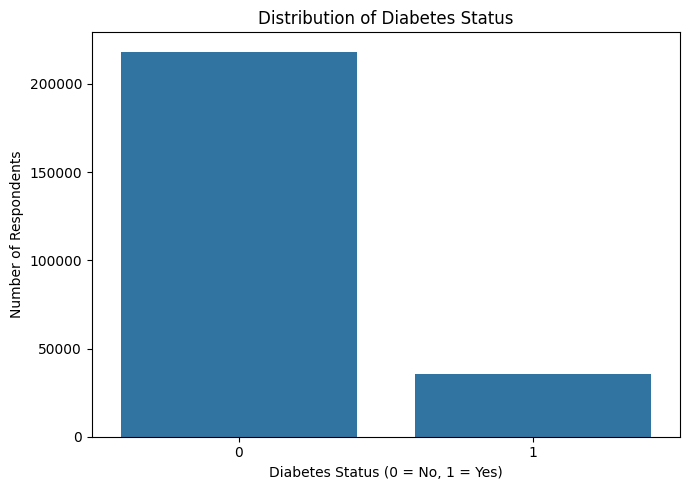

In [13]:

import matplotlib.pyplot as plt
import seaborn as sns

# Count the two target classes
target_counts = df["Diabetes_binary"].value_counts().sort_index()

print("Target class counts:")
print(target_counts)

print("\nTarget class percentages:")
print((df["Diabetes_binary"].value_counts(normalize=True).sort_index() * 100).round(2))

# Plot the target distribution
plt.figure(figsize=(7, 5))
sns.countplot(data=df, x="Diabetes_binary")
plt.title("Distribution of Diabetes Status")
plt.xlabel("Diabetes Status (0 = No, 1 = Yes)")
plt.ylabel("Number of Respondents")
plt.tight_layout()
plt.show()

Diabetes status by high blood pressure (%):
                No Diabetes (0)  Diabetes (1)
No High BP (0)            93.96          6.04
High BP (1)               75.55         24.45


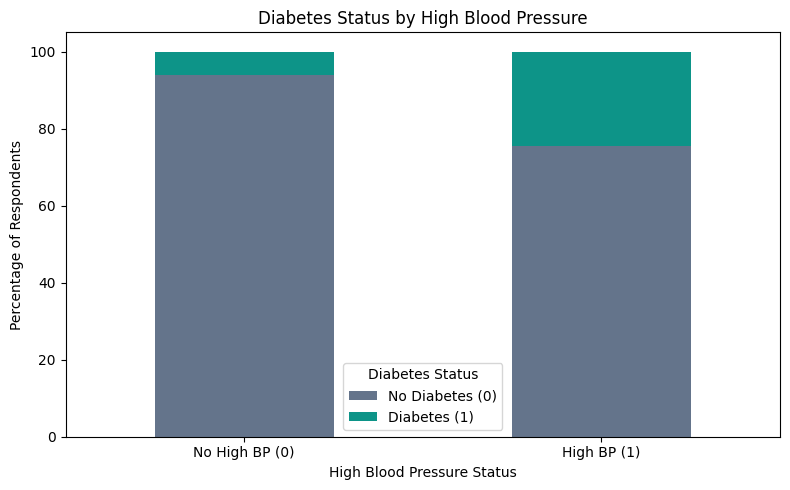

In [14]:

import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Calculate diabetes percentages by high blood pressure status
bp_table = pd.crosstab(
    df["HighBP"],
    df["Diabetes_binary"],
    normalize="index"
) * 100

bp_table.index = ["No High BP (0)", "High BP (1)"]
bp_table.columns = ["No Diabetes (0)", "Diabetes (1)"]

print("Diabetes status by high blood pressure (%):")
print(bp_table.round(2))

# Plot the percentages
bp_table.plot(
    kind="bar",
    stacked=True,
    figsize=(8, 5),
    color=["#64748b", "#0d9488"]
)

plt.title("Diabetes Status by High Blood Pressure")
plt.xlabel("High Blood Pressure Status")
plt.ylabel("Percentage of Respondents")
plt.xticks(rotation=0)
plt.legend(title="Diabetes Status")
plt.tight_layout()
plt.show()

In [15]:

from pathlib import Path

file_path = Path(
    "/content/drive/MyDrive/PhD/ML Coursework Project/01 CDC Diabetes/Dataset/CDC_Diabetes_Health_Indicators.csv"
)

print("File exists:", file_path.exists())
print("Full path:", file_path)
print("Dataset folder contents:")

if file_path.parent.exists():
    for item in file_path.parent.iterdir():
        print(item.name)
else:
    print("Dataset folder does not exist at this path.")

File exists: True
Full path: /content/drive/MyDrive/PhD/ML Coursework Project/01 CDC Diabetes/Dataset/CDC_Diabetes_Health_Indicators.csv
Dataset folder contents:
CDC_Diabetes_Health_Indicators.csv


In [16]:

from google.colab import drive
from pathlib import Path

folder = Path(
    "/content/drive/MyDrive/PhD/ML Coursework Project/01 CDC Diabetes/Dataset"
)

print("Files saved in Dataset folder:")
for file in folder.iterdir():
    print("📄", file.name)

print("\nOpen Google Drive in your browser:")
print("https://drive.google.com/drive/my-drive")

Files saved in Dataset folder:
📄 CDC_Diabetes_Health_Indicators.csv

Open Google Drive in your browser:
https://drive.google.com/drive/my-drive


In [17]:

from pathlib import Path

base = Path("/content/drive/MyDrive")

print("Folders inside My Drive:")
for item in base.iterdir():
    print("📁" if item.is_dir() else "📄", repr(item.name))

print("\nFolders inside PhD:")
phd = base / "PhD"
if phd.exists():
    for item in phd.iterdir():
        print("📁" if item.is_dir() else "📄", repr(item.name))
else:
    print("PhD folder not found")

Folders inside My Drive:
📁 'PhD'

Folders inside PhD:
📁 'ML Coursework Project'


In [18]:

from pathlib import Path

project = Path(
    "/content/drive/MyDrive/PhD/ML Coursework Project"
)

print("Folders and files inside ML Coursework Project:\n")

for item in project.iterdir():
    print("📁" if item.is_dir() else "📄", item.name)

cdc = project / "01 CDC Diabetes"

print("\nDoes 01 CDC Diabetes exist?", cdc.exists())

if cdc.exists():
    print("\nContents of 01 CDC Diabetes:")
    for item in cdc.iterdir():
        print("📁" if item.is_dir() else "📄", item.name)

Folders and files inside ML Coursework Project:

📁 01 CDC Diabetes

Does 01 CDC Diabetes exist? True

Contents of 01 CDC Diabetes:
📁 Dataset


In [19]:

from pathlib import Path

folder = Path(
    "/content/drive/MyDrive/PhD/ML Coursework Project/01 CDC Diabetes/Dataset"
)

file_path = folder / "CDC_Diabetes_Health_Indicators.csv"

print("Dataset folder exists:", folder.exists())
print("CSV exists:", file_path.exists())

if file_path.exists():
    print("File size:", round(file_path.stat().st_size / (1024 * 1024), 2), "MB")
    print("Last modified:", file_path.stat().st_mtime)

print("\nFull folder path:")
print(folder)

Dataset folder exists: True
CSV exists: True
File size: 11.04 MB
Last modified: 1790684567.1182966

Full folder path:
/content/drive/MyDrive/PhD/ML Coursework Project/01 CDC Diabetes/Dataset


In [20]:

from pathlib import Path
import shutil

source = Path(
    "/content/drive/MyDrive/PhD/ML Coursework Project/01 CDC Diabetes/Dataset/CDC_Diabetes_Health_Indicators.csv"
)

backup = Path(
    "/content/drive/MyDrive/CDC_Diabetes_Backup.csv"
)

shutil.copy2(source, backup)

print("Backup exists:", backup.exists())
print("Backup size (MB):", round(backup.stat().st_size / (1024 * 1024), 2))
print("Backup location:", backup)

Backup exists: True
Backup size (MB): 11.04
Backup location: /content/drive/MyDrive/CDC_Diabetes_Backup.csv


In [21]:

from pathlib import Path

base = Path("/content/drive/MyDrive")

print("Top-level files and folders:")
for item in base.iterdir():
    print(item.name)

backup = base / "CDC_Diabetes_Backup.csv"
original = base / "PhD/ML Coursework Project/01 CDC Diabetes/Dataset/CDC_Diabetes_Health_Indicators.csv"

print("\nBackup exists:", backup.exists())
print("Original exists:", original.exists())

Top-level files and folders:
PhD
CDC_Diabetes_Backup.csv

Backup exists: True
Original exists: True


In [22]:

from google.colab import drive

drive.flush_and_unmount()
print("Google Drive disconnected safely.")

Drive not mounted, so nothing to flush and unmount.
Google Drive disconnected safely.


In [23]:

from google.colab import drive

drive.mount('/content/drive')

ValueError: Mountpoint must not already contain files

In [24]:

import os

mount_path = "/content/drive"

print("Drive path exists:", os.path.exists(mount_path))
print("Is a directory:", os.path.isdir(mount_path))

if os.path.isdir(mount_path):
    print("Contents:", os.listdir(mount_path))

Drive path exists: True
Is a directory: True
Contents: ['MyDrive']


In [25]:

from pathlib import Path
import pandas as pd

base = Path("/content/drive/MyDrive")

original = base / "PhD/ML Coursework Project/01 CDC Diabetes/Dataset/CDC_Diabetes_Health_Indicators.csv"
backup = base / "CDC_Diabetes_Backup.csv"

for path in [original, backup]:
    print("\nFile:", path)
    print("Exists:", path.exists())

    if path.exists():
        try:
            test_df = pd.read_csv(path, nrows=5)
            print("Readable: Yes")
            print("Columns:", len(test_df.columns))
            print("File size (MB):", round(path.stat().st_size / (1024 * 1024), 2))
        except Exception as e:
            print("Read error:", repr(e))


File: /content/drive/MyDrive/PhD/ML Coursework Project/01 CDC Diabetes/Dataset/CDC_Diabetes_Health_Indicators.csv
Exists: True
Readable: Yes
Columns: 22
File size (MB): 11.04

File: /content/drive/MyDrive/CDC_Diabetes_Backup.csv
Exists: True
Readable: Yes
Columns: 22
File size (MB): 11.04


In [26]:

from google.colab import files

file_path = "/content/drive/MyDrive/PhD/ML Coursework Project/01 CDC Diabetes/Dataset/CDC_Diabetes_Health_Indicators.csv"

files.download(file_path)

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

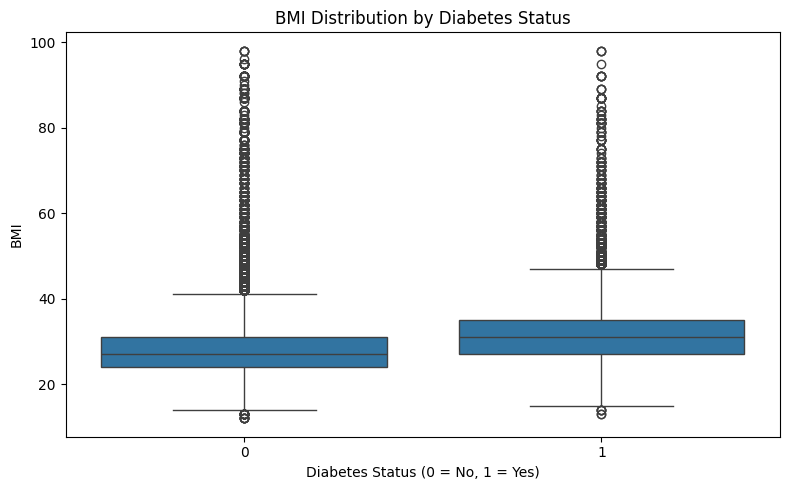

BMI summary by diabetes status:
                    count   mean   std   min   25%   50%   75%   max
Diabetes_binary                                                     
0                218334.0  27.81  6.29  12.0  24.0  27.0  31.0  98.0
1                 35346.0  31.94  7.36  13.0  27.0  31.0  35.0  98.0


In [27]:

import matplotlib.pyplot as plt
import seaborn as sns

# Compare BMI across diabetes-status groups
plt.figure(figsize=(8, 5))

sns.boxplot(
    data=df,
    x="Diabetes_binary",
    y="BMI"
)

plt.title("BMI Distribution by Diabetes Status")
plt.xlabel("Diabetes Status (0 = No, 1 = Yes)")
plt.ylabel("BMI")
plt.tight_layout()
plt.show()

# Summarise BMI in each group
print("BMI summary by diabetes status:")
print(
    df.groupby("Diabetes_binary")["BMI"]
      .describe()
      .round(2)
)

Diabetes status by age category (%):
     No Diabetes (%)  Diabetes (%)
Age                               
1              98.63          1.37
2              98.16          1.84
3              97.18          2.82
4              95.47          4.53
5              93.50          6.50
6              91.21          8.79
7              88.26         11.74
8              86.17         13.83
9              82.75         17.25
10             79.63         20.37
11             78.15         21.85
12             78.70         21.30
13             81.52         18.48


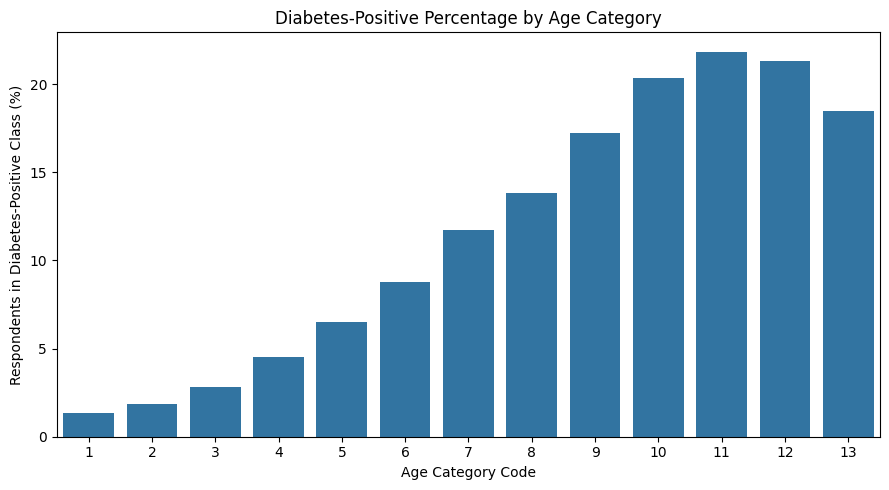

In [28]:

import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Calculate diabetes percentages within each age category
age_table = pd.crosstab(
    df["Age"],
    df["Diabetes_binary"],
    normalize="index"
) * 100

age_table.columns = ["No Diabetes (%)", "Diabetes (%)"]

print("Diabetes status by age category (%):")
print(age_table.round(2))

# Plot diabetes-positive percentage by age category
plt.figure(figsize=(9, 5))

sns.barplot(
    x=age_table.index,
    y=age_table["Diabetes (%)"]
)

plt.title("Diabetes-Positive Percentage by Age Category")
plt.xlabel("Age Category Code")
plt.ylabel("Respondents in Diabetes-Positive Class (%)")
plt.tight_layout()
plt.show()

Diabetes status by general health category (%):
         No Diabetes (%)  Diabetes (%)
GenHlth                               
1                  97.48          2.52
2                  92.84          7.16
3                  82.21         17.79
4                  68.99         31.01
5                  62.11         37.89


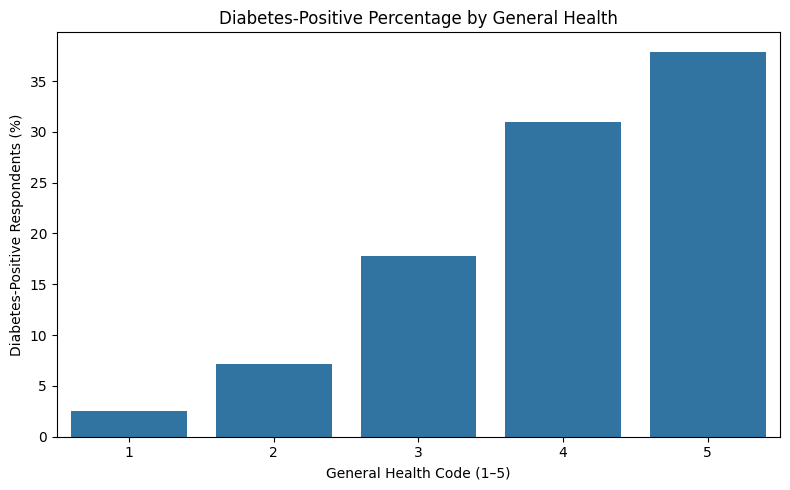

In [29]:

import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Calculate diabetes-positive percentages within each health category
health_table = pd.crosstab(
    df["GenHlth"],
    df["Diabetes_binary"],
    normalize="index"
) * 100

health_table.columns = ["No Diabetes (%)", "Diabetes (%)"]

print("Diabetes status by general health category (%):")
print(health_table.round(2))

# Plot the results
plt.figure(figsize=(8, 5))

sns.barplot(
    x=health_table.index,
    y=health_table["Diabetes (%)"]
)

plt.title("Diabetes-Positive Percentage by General Health")
plt.xlabel("General Health Code (1–5)")
plt.ylabel("Diabetes-Positive Respondents (%)")
plt.tight_layout()
plt.show()

In [30]:

chol_table = pd.crosstab(
    df["HighChol"],
    df["Diabetes_binary"],
    normalize="index"
) * 100

chol_table.index = ["No High Cholesterol (0)", "High Cholesterol (1)"]
chol_table.columns = ["No Diabetes (%)", "Diabetes (%)"]

print("Diabetes status by high cholesterol (%):")
print(chol_table.round(2))

Diabetes status by high cholesterol (%):
                         No Diabetes (%)  Diabetes (%)
No High Cholesterol (0)            92.02          7.98
High Cholesterol (1)               77.99         22.01


In [31]:

activity_table = pd.crosstab(
    df["PhysActivity"],
    df["Diabetes_binary"],
    normalize="index"
) * 100

activity_table.index = [
    "No physical activity (0)",
    "Physical activity (1)"
]
activity_table.columns = [
    "No Diabetes (%)",
    "Diabetes (%)"
]

print("Diabetes status by physical activity (%):")
print(activity_table.round(2))

Diabetes status by physical activity (%):
                          No Diabetes (%)  Diabetes (%)
No physical activity (0)            78.86         21.14
Physical activity (1)               88.39         11.61


In [32]:
combined_table = pd.crosstab(
    [df["HighBP"], df["HighChol"]],
    df["Diabetes_binary"],
    normalize="index"
) * 100

combined_table.columns = [
    "No Diabetes (%)",
    "Diabetes (%)"
]

print("Diabetes status by blood pressure and cholesterol (%):")
print(combined_table.round(2))

Diabetes status by blood pressure and cholesterol (%):
                 No Diabetes (%)  Diabetes (%)
HighBP HighChol                               
0      0                   95.81          4.19
       1                   89.58         10.42
1      0                   83.27         16.73
       1                   70.29         29.71


In [33]:
age_table = pd.crosstab(
    df["Age"],
    df["Diabetes_binary"],
    normalize="index"
) * 100

age_table.columns = [
    "No Diabetes (%)",
    "Diabetes (%)"
]

print("Diabetes status by age category (%):")
print(age_table.round(2))

Diabetes status by age category (%):
     No Diabetes (%)  Diabetes (%)
Age                               
1              98.63          1.37
2              98.16          1.84
3              97.18          2.82
4              95.47          4.53
5              93.50          6.50
6              91.21          8.79
7              88.26         11.74
8              86.17         13.83
9              82.75         17.25
10             79.63         20.37
11             78.15         21.85
12             78.70         21.30
13             81.52         18.48


In [34]:
income_table = pd.crosstab(
    df["Income"],
    df["Diabetes_binary"],
    normalize="index"
) * 100

income_table.columns = [
    "No Diabetes (%)",
    "Diabetes (%)"
]

print("Diabetes status by income category (%):")
print(income_table.round(2))

Diabetes status by income category (%):
        No Diabetes (%)  Diabetes (%)
Income                               
1                 75.71         24.29
2                 73.81         26.19
3                 77.69         22.31
4                 79.87         20.13
5                 82.60         17.40
6                 85.49         14.51
7                 87.82         12.18
8                 92.04          7.96


In [35]:
education_table = pd.crosstab(
    df["Education"],
    df["Diabetes_binary"],
    normalize="index"
) * 100

education_table.columns = [
    "No Diabetes (%)",
    "Diabetes (%)"
]

print("Diabetes status by education category (%):")
print(education_table.round(2))

Diabetes status by education category (%):
           No Diabetes (%)  Diabetes (%)
Education                               
1                    72.99         27.01
2                    70.74         29.26
3                    75.78         24.22
4                    82.36         17.64
5                    85.19         14.81
6                    90.31          9.69


In [36]:
print("Dataset shape:", df.shape)

print("\nTarget values:")
print(df["Diabetes_binary"].value_counts().sort_index())

print("\nAge categories:")
print(sorted(df["Age"].unique()))

print("\nEducation categories:")
print(sorted(df["Education"].unique()))

print("\nIncome categories:")
print(sorted(df["Income"].unique()))

Dataset shape: (253680, 22)

Target values:
Diabetes_binary
0    218334
1     35346
Name: count, dtype: int64

Age categories:
[np.int64(1), np.int64(2), np.int64(3), np.int64(4), np.int64(5), np.int64(6), np.int64(7), np.int64(8), np.int64(9), np.int64(10), np.int64(11), np.int64(12), np.int64(13)]

Education categories:
[np.int64(1), np.int64(2), np.int64(3), np.int64(4), np.int64(5), np.int64(6)]

Income categories:
[np.int64(1), np.int64(2), np.int64(3), np.int64(4), np.int64(5), np.int64(6), np.int64(7), np.int64(8)]


Data Preparation for Machine Learning

In [37]:
# Separate input features and target variable

X = df.drop('Diabetes_binary', axis=1)
y = df['Diabetes_binary']

print("Input features shape:", X.shape)
print("Target variable shape:", y.shape)

Input features shape: (253680, 21)
Target variable shape: (253680,)


In [38]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("Training features:", X_train.shape)
print("Testing features:", X_test.shape)
print("Training target:", y_train.shape)
print("Testing target:", y_test.shape)

Training features: (202944, 21)
Testing features: (50736, 21)
Training target: (202944,)
Testing target: (50736,)


In [39]:
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, classification_report

# Create the model
logistic_model = LogisticRegression(
    max_iter=1000,
    random_state=42
)

# Train the model using the training data
logistic_model.fit(X_train, y_train)

# Predict outcomes for the test data
y_pred = logistic_model.predict(X_test)

# Evaluate the predictions
print("Accuracy:", accuracy_score(y_test, y_pred))
print("\nClassification Report:\n")
print(classification_report(y_test, y_pred))

Accuracy: 0.8622082939135919

Classification Report:

              precision    recall  f1-score   support

           0       0.88      0.98      0.92     43667
           1       0.52      0.16      0.24      7069

    accuracy                           0.86     50736
   macro avg       0.70      0.57      0.58     50736
weighted avg       0.83      0.86      0.83     50736



### Logistic Regression — Preliminary Results

The Logistic Regression model achieved an overall accuracy of 86.22% on the test set. The recall for class 0 was 98%, whereas the recall for class 1 (prediabetes or diabetes) was only 16%. The F1-score for class 1 was 0.24.

These results suggest that overall accuracy alone is insufficient for evaluating this model on the imbalanced dataset. Further experiments will compare different classification models using precision, recall, F1-score and other appropriate evaluation metrics, with particular attention to class 1.


Model 2: Decision Tree Classifier

In [40]:
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import accuracy_score, classification_report

# Create the Decision Tree model
tree_model = DecisionTreeClassifier(
    random_state=42,
    class_weight='balanced'
)

# Train the model
tree_model.fit(X_train, y_train)

# Predict on the test data
y_pred_tree = tree_model.predict(X_test)

# Evaluate the model
print("Decision Tree Accuracy:", accuracy_score(y_test, y_pred_tree))
print("\nClassification Report:\n")
print(classification_report(y_test, y_pred_tree))

Decision Tree Accuracy: 0.7977175969725638

Classification Report:

              precision    recall  f1-score   support

           0       0.89      0.88      0.88     43667
           1       0.28      0.30      0.29      7069

    accuracy                           0.80     50736
   macro avg       0.58      0.59      0.59     50736
weighted avg       0.80      0.80      0.80     50736



### Decision Tree — Preliminary Results

The Decision Tree classifier achieved an accuracy of 79.77% on the test set. The recall for class 1 (prediabetes or diabetes) was 30%, with a precision of 28% and an F1-score of 0.29.

Compared with Logistic Regression, the Decision Tree achieved higher recall and F1-score for class 1 but lower overall accuracy and precision for that class. These preliminary results illustrate the importance of considering multiple evaluation metrics when comparing classifiers on an imbalanced dataset. Further models will be evaluated using the same test set.


Model 3: Random Forest Classifier

In [41]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, classification_report

# Create the Random Forest model
rf_model = RandomForestClassifier(
    n_estimators=100,
    random_state=42,
    class_weight='balanced',
    n_jobs=-1
)

# Train the model
rf_model.fit(X_train, y_train)

# Predict on the test data
y_pred_rf = rf_model.predict(X_test)

# Evaluate the model
print("Random Forest Accuracy:", accuracy_score(y_test, y_pred_rf))
print("\nClassification Report:\n")
print(classification_report(y_test, y_pred_rf))

Random Forest Accuracy: 0.8576750236518449

Classification Report:

              precision    recall  f1-score   support

           0       0.88      0.97      0.92     43667
           1       0.47      0.16      0.24      7069

    accuracy                           0.86     50736
   macro avg       0.67      0.57      0.58     50736
weighted avg       0.82      0.86      0.83     50736



### Random Forest — Preliminary Results

The Random Forest classifier achieved an accuracy of 85.77% on the test set. For class 1 (prediabetes or diabetes), precision was 47%, recall was 16%, and the F1-score was 0.24.

Compared with Logistic Regression, Random Forest achieved slightly lower accuracy and class 1 precision, while class 1 recall and F1-score were similar. Compared with the Decision Tree, Random Forest achieved higher accuracy and precision but lower recall and F1-score for class 1.

These results demonstrate that different classifiers can show different performance patterns on an imbalanced dataset. Further evaluation and comparison are needed.


Comparative Analysis of Machine Learning Models

In [48]:
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score
import pandas as pd

results = []

models = {
    "Logistic Regression": y_pred,
    "Decision Tree": y_pred_tree,
    "Random Forest": y_pred_rf,
    "Gaussian Naive Bayes": y_pred_nb,
    "Linear SVM": y_pred_svm
}

for model_name, predictions in models.items():
    results.append({
        "Model": model_name,
        "Accuracy": accuracy_score(y_test, predictions),
        "Class 1 Precision": precision_score(
            y_test, predictions, pos_label=1, zero_division=0
        ),
        "Class 1 Recall": recall_score(
            y_test, predictions, pos_label=1, zero_division=0
        ),
        "Class 1 F1-score": f1_score(
            y_test, predictions, pos_label=1, zero_division=0
        )
    })

comparison_df = pd.DataFrame(results)

comparison_df.round(3).style.hide(axis="index")

Model,Accuracy,Class 1 Precision,Class 1 Recall,Class 1 F1-score
Logistic Regression,0.862000,0.518000,0.158000,0.242000
Decision Tree,0.798000,0.284000,0.296000,0.290000
Random Forest,0.858000,0.469000,0.160000,0.239000
Gaussian Naive Bayes,0.772000,0.320000,0.564000,0.408000
Linear SVM,0.727000,0.308000,0.769000,0.440000


In [45]:
comparison_df.round(3).style.hide(axis="index")

Model,Accuracy,Class 1 Precision,Class 1 Recall,Class 1 F1-score
Logistic Regression,0.862000,0.518000,0.158000,0.242000
Decision Tree,0.798000,0.284000,0.296000,0.290000
Random Forest,0.858000,0.469000,0.160000,0.239000


### Comparative Analysis of the Three Classification Models

Three classification models were evaluated using the same training and testing split. Logistic Regression achieved the highest accuracy (86.22%), followed by Random Forest (85.77%) and Decision Tree (79.77%).

For class 1 (prediabetes or diabetes), the Decision Tree achieved the highest recall (29.6%) and F1-score (0.290). Logistic Regression and Random Forest achieved higher precision for class 1 but lower recall.

These results indicate that overall accuracy and the ability to identify class 1 records provide different perspectives on model performance. Since class 1 is the minority class, further experiments are needed to investigate whether other classifiers or training strategies can improve its detection.


Comparative Analysis of Machine Learning Models

### Comparative Analysis of Machine Learning Models

Five classification models were evaluated using the same training and testing split. Their performance was compared using accuracy, class 1 precision, class 1 recall, and class 1 F1-score.

Logistic Regression achieved the highest accuracy (86.2%), followed by Random Forest (85.8%). The Decision Tree achieved an accuracy of 79.8%, Gaussian Naive Bayes achieved 77.2%, and Linear SVM achieved 72.7%.

For class 1 (prediabetes or diabetes), Linear SVM achieved the highest recall (76.9%) and F1-score (0.440), followed by Gaussian Naive Bayes, with a recall of 56.4% and an F1-score of 0.408. Logistic Regression and Random Forest had higher class 1 precision but substantially lower recall.

These results illustrate that model performance varies depending on the evaluation metric. In this imbalanced dataset, models with higher overall accuracy did not necessarily identify a larger proportion of class 1 records. Therefore, accuracy should be considered alongside precision, recall, and F1-score when comparing these classifiers.

The results are preliminary and describe associations in this dataset; they do not establish clinical diagnostic performance or causation.


Model 4: Gaussian Naive Bayes

In [46]:
from sklearn.naive_bayes import GaussianNB
from sklearn.metrics import accuracy_score, classification_report

# Create the Gaussian Naive Bayes model
nb_model = GaussianNB()

# Train the model
nb_model.fit(X_train, y_train)

# Predict on the test data
y_pred_nb = nb_model.predict(X_test)

# Evaluate the model
print("Gaussian Naive Bayes Accuracy:",
      accuracy_score(y_test, y_pred_nb))

print("\nClassification Report:\n")
print(classification_report(y_test, y_pred_nb))

Gaussian Naive Bayes Accuracy: 0.7721538946704509

Classification Report:

              precision    recall  f1-score   support

           0       0.92      0.81      0.86     43667
           1       0.32      0.56      0.41      7069

    accuracy                           0.77     50736
   macro avg       0.62      0.68      0.63     50736
weighted avg       0.84      0.77      0.80     50736



### Gaussian Naive Bayes — Preliminary Results

The Gaussian Naive Bayes classifier achieved an accuracy of 77.22% on the test set. For class 1 (prediabetes or diabetes), the model achieved a precision of 32%, a recall of 56%, and an F1-score of 0.41.

Compared with the three previously evaluated models, Gaussian Naive Bayes achieved higher recall and F1-score for class 1, but lower overall accuracy. This suggests that it identified a larger proportion of class 1 records, while also producing more false-positive predictions.

These preliminary results highlight the importance of evaluating multiple performance metrics when working with an imbalanced dataset.


Model 5: Linear Support Vector Machine (SVM)

In [47]:
from sklearn.svm import LinearSVC
from sklearn.metrics import accuracy_score, classification_report

# Create the SVM model
svm_model = LinearSVC(
    class_weight='balanced',
    random_state=42,
    max_iter=2000
)

# Train the model
svm_model.fit(X_train, y_train)

# Predict on the test data
y_pred_svm = svm_model.predict(X_test)

# Evaluate the model
print("Linear SVM Accuracy:", accuracy_score(y_test, y_pred_svm))
print("\nClassification Report:\n")
print(classification_report(y_test, y_pred_svm))

Linear SVM Accuracy: 0.7274716177861873

Classification Report:

              precision    recall  f1-score   support

           0       0.95      0.72      0.82     43667
           1       0.31      0.77      0.44      7069

    accuracy                           0.73     50736
   macro avg       0.63      0.74      0.63     50736
weighted avg       0.86      0.73      0.77     50736



### Linear SVM — Preliminary Results

The Linear Support Vector Machine (SVM) classifier achieved an accuracy of 72.75% on the test set. For class 1 (prediabetes or diabetes), the model achieved a precision of 31%, a recall of 77%, and an F1-score of 0.44.

Compared with the previously evaluated models, Linear SVM achieved the highest recall and F1-score for class 1. However, its overall accuracy was lower, and its class 1 precision was 31%, indicating that many positive predictions were false positives.

These results illustrate a trade-off between identifying a larger proportion of class 1 records and correctly identifying the predicted positive records. Further comparative evaluation is needed.


Visual Comparison of Machine Learning Models

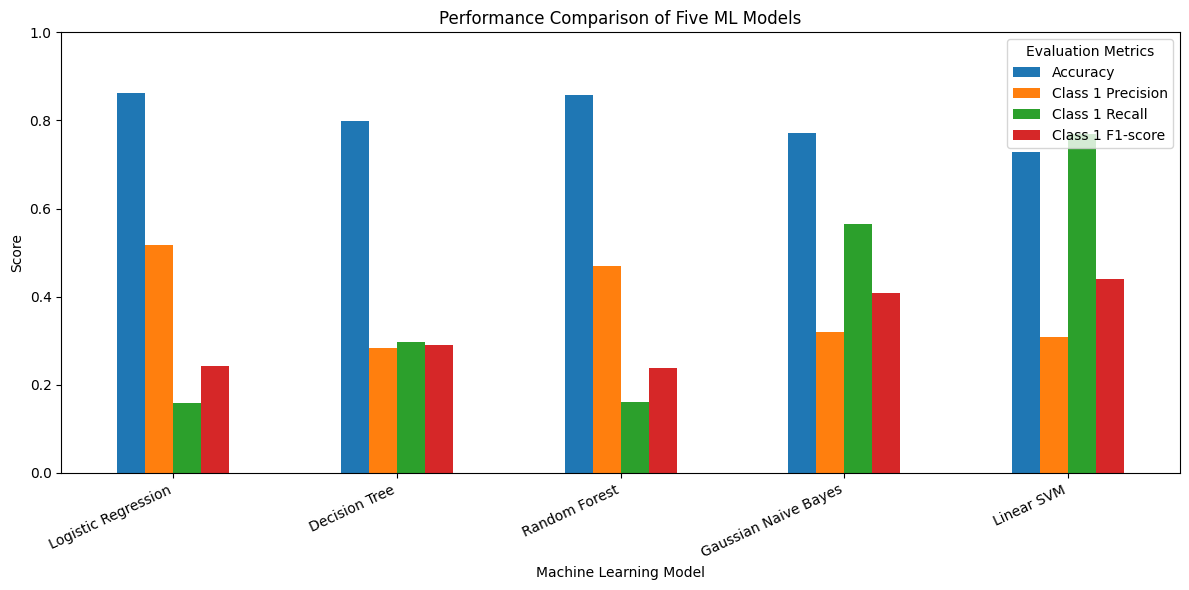

In [49]:
import matplotlib.pyplot as plt
import pandas as pd

# Select the performance metrics to compare
metrics = [
    "Accuracy",
    "Class 1 Precision",
    "Class 1 Recall",
    "Class 1 F1-score"
]

# Prepare the comparison chart
plot_df = comparison_df.set_index("Model")[metrics]

# Create a grouped bar chart
plot_df.plot(kind="bar", figsize=(12, 6))

plt.title("Performance Comparison of Five ML Models")
plt.ylabel("Score")
plt.xlabel("Machine Learning Model")
plt.ylim(0, 1)
plt.xticks(rotation=25, ha="right")
plt.legend(title="Evaluation Metrics")
plt.tight_layout()
plt.show()

Confusion Matrix — Linear SVM

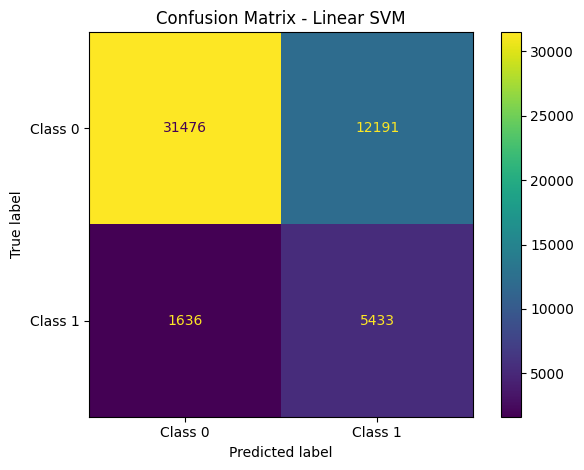

In [50]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
import matplotlib.pyplot as plt

# Calculate the confusion matrix
cm = confusion_matrix(y_test, y_pred_svm)

# Display the confusion matrix
disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=["Class 0", "Class 1"]
)

disp.plot()
plt.title("Confusion Matrix - Linear SVM")
plt.tight_layout()
plt.show()

### Interpretation of the Confusion Matrix — Linear SVM

The confusion matrix shows that the Linear SVM classifier correctly classified 31,476 class 0 records and 5,433 class 1 records. It incorrectly classified 12,191 class 0 records as class 1 (false positives) and 1,636 class 1 records as class 0 (false negatives).

The model identified a substantial proportion of actual class 1 records, consistent with its class 1 recall of approximately 76.9%. However, the number of false-positive predictions was also high, resulting in a class 1 precision of approximately 30.8%.

These results illustrate the trade-off between identifying class 1 records and limiting false-positive predictions. The confusion matrix provides additional detail that cannot be understood from accuracy alone.


Confusion Matrices — Comparison of All Five Models

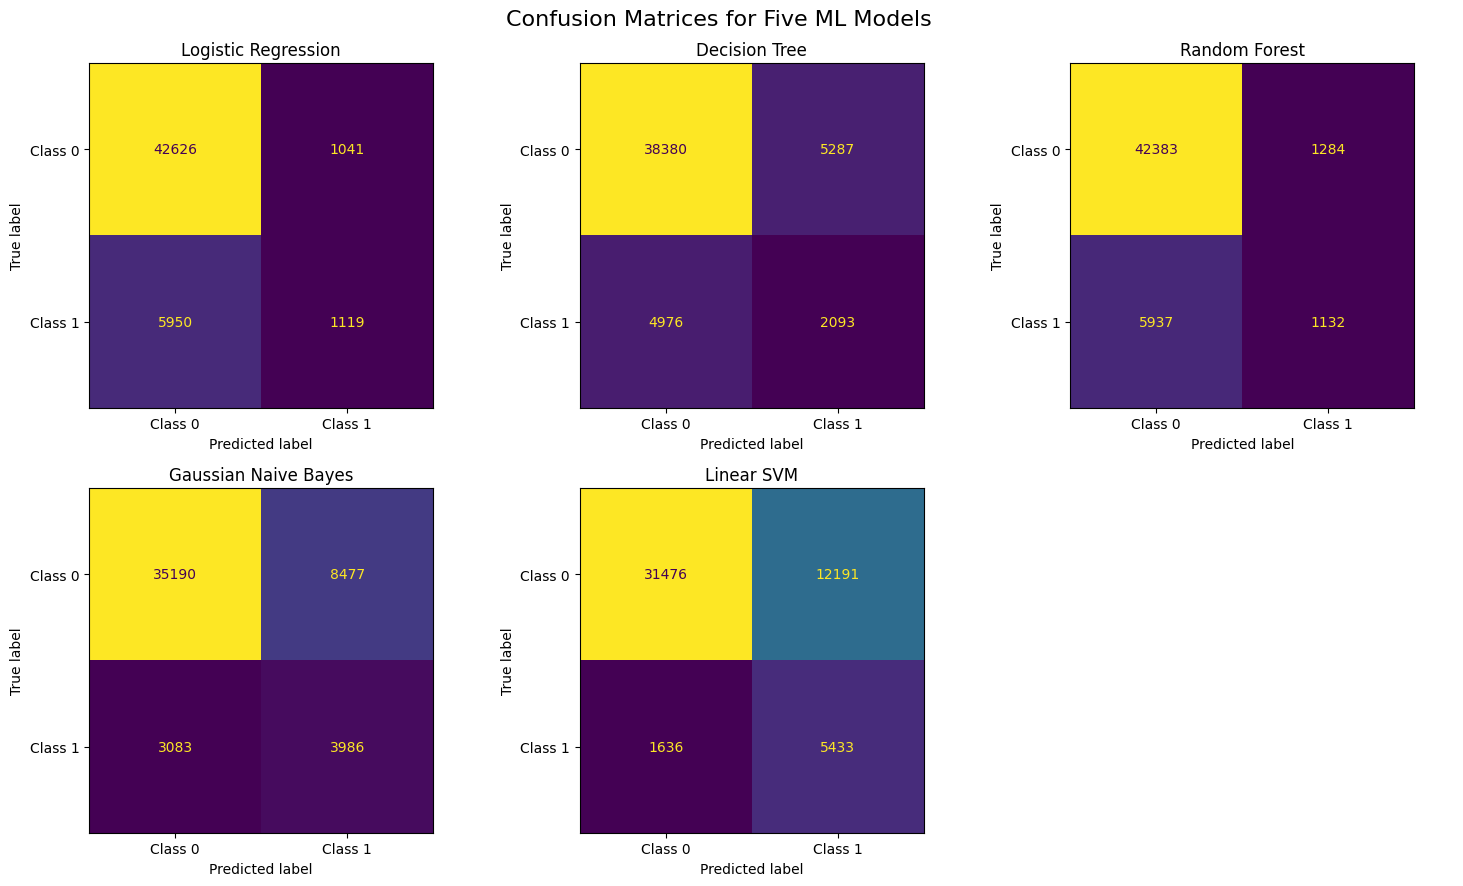

In [51]:
import matplotlib.pyplot as plt
from sklearn.metrics import ConfusionMatrixDisplay
from sklearn.metrics import confusion_matrix

models_for_cm = {
    "Logistic Regression": y_pred,
    "Decision Tree": y_pred_tree,
    "Random Forest": y_pred_rf,
    "Gaussian Naive Bayes": y_pred_nb,
    "Linear SVM": y_pred_svm
}

fig, axes = plt.subplots(2, 3, figsize=(15, 9))
axes = axes.flatten()

for i, (model_name, predictions) in enumerate(models_for_cm.items()):
    cm = confusion_matrix(y_test, predictions)

    disp = ConfusionMatrixDisplay(
        confusion_matrix=cm,
        display_labels=["Class 0", "Class 1"]
    )

    disp.plot(ax=axes[i], colorbar=False, values_format="d")
    axes[i].set_title(model_name)

# Hide the unused sixth panel
axes[5].axis("off")

plt.suptitle("Confusion Matrices for Five ML Models", fontsize=16)
plt.tight_layout()
plt.show()

### Comparative Interpretation of Confusion Matrices

The confusion matrices provide a detailed comparison of the classification errors made by the five machine learning models.

Logistic Regression and Random Forest achieved higher overall accuracy, but their confusion matrices show that they missed a substantial proportion of class 1 (prediabetes or diabetes) records. In contrast, Gaussian Naive Bayes and Linear SVM identified a larger proportion of class 1 records, although they also produced more false-positive predictions.

The Decision Tree showed an intermediate pattern in class 1 recall compared with the other models.

These findings are consistent with the classification reports and comparative performance table. They demonstrate that evaluating both correct predictions and classification errors is important when comparing models on an imbalanced dataset.


Feature Importance Analysis — Random Forest

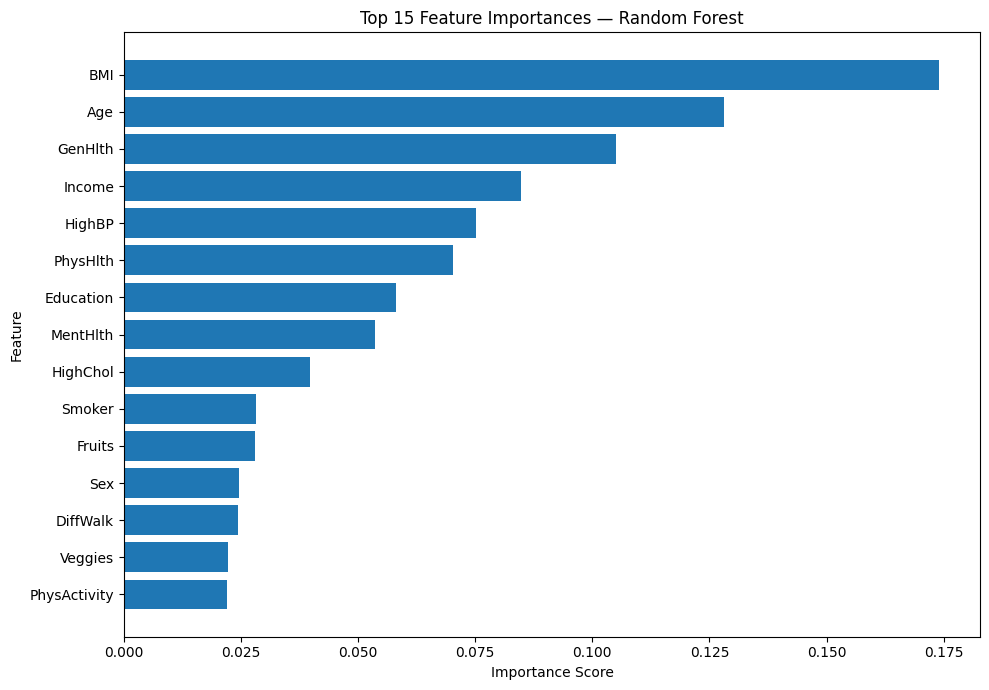

In [52]:
import pandas as pd
import matplotlib.pyplot as plt

# Extract feature importance from the trained Random Forest
feature_importance = pd.DataFrame({
    "Feature": X_train.columns,
    "Importance": rf_model.feature_importances_
})

# Sort features from highest to lowest importance
feature_importance = feature_importance.sort_values(
    by="Importance", ascending=False
)

# Display the top 15 features
top_features = feature_importance.head(15).sort_values(
    by="Importance", ascending=True
)

# Create a horizontal bar chart
plt.figure(figsize=(10, 7))
plt.barh(top_features["Feature"], top_features["Importance"])

plt.title("Top 15 Feature Importances — Random Forest")
plt.xlabel("Importance Score")
plt.ylabel("Feature")
plt.tight_layout()
plt.show()

### Interpretation of Random Forest Feature Importance

The Random Forest feature importance analysis identified BMI, Age, and GenHlth (general health rating) as the three most important features in the trained model.

BMI ranked highest, followed by Age and GenHlth. These results indicate that the model relied relatively more on these features when making its classification decisions.

However, feature importance does not establish a causal relationship between these variables and diabetes or prediabetes. The results describe the behaviour of the trained model on this dataset and should be interpreted as exploratory findings.


Overall Findings and Conclusion

### Overall Findings

This study evaluated five machine learning classification models using the CDC Diabetes Health Indicators dataset: Logistic Regression, Decision Tree, Random Forest, Gaussian Naive Bayes, and Linear Support Vector Machine (SVM).

The models showed different performance patterns across accuracy, precision, recall, and F1-score. Logistic Regression achieved the highest overall accuracy (86.2%), while Linear SVM achieved the highest recall (76.9%) and F1-score (0.440) for class 1 (prediabetes or diabetes) among the five evaluated models.

Gaussian Naive Bayes also demonstrated relatively high class 1 recall (56.4%) and an F1-score of 0.408. In comparison, Logistic Regression and Random Forest had lower class 1 recall despite their higher overall accuracy.

The Random Forest feature importance analysis identified BMI, Age, and GenHlth (general health rating) as the three highest-ranked features in the trained model. These findings describe model behaviour and do not establish causal relationships.

### Conclusion

This project demonstrates the importance of comparing multiple evaluation metrics when assessing machine learning classifiers on an imbalanced dataset. Overall accuracy alone does not fully describe a model's ability to identify records belonging to the minority class.

The preliminary results show that the five models differ in their balance between overall accuracy and the identification of class 1 records. Further investigation, including additional validation and evaluation of model limitations, would be useful before drawing broader conclusions.

The models are intended for academic investigation and are not clinical diagnostic tools.


**Literature Review**

### Paper 1: Enhancing Diabetes Risk Prediction: A Comparative Evaluation of Bagging, Boosting, and Ensemble Classifiers with SMOTE Oversampling (2025)

**Objective:** The study investigates machine learning approaches for diabetes-risk prediction, focusing on ensemble methods, feature selection, class imbalance and model optimisation.

**Methodology:** The researchers use Weighted Feature Importance (WFI) for feature selection, SMOTE for minority-class oversampling, five-fold cross-validation and GridSearchCV for hyperparameter tuning. They describe two experimental approaches: applying SMOTE before a 70:30 train-test split and applying SMOTE only to the training data after an 80:20 split.

**Relevance to the present project:** The study is relevant because it uses the CDC Diabetes Health Indicators dataset and investigates classification performance under class imbalance. It provides a basis for considering data-splitting procedures, class-imbalance handling and model evaluation when comparing classifiers.

**Further information to extract:** The specific models evaluated on the CDC dataset, their class-wise precision and recall, F1-scores, confusion matrices, and the results obtained when SMOTE is applied only to training data.


Enhancing Diabetes Risk Prediction: A Comparative Evaluation of Bagging, Boosting, and Ensemble Classifiers with SMOTE Oversampling

2025 · Informatics in Medicine Unlocked

Research objective

To compare diabetes classification methods, feature selection techniques and strategies for handling class imbalance across three datasets, including the CDC Diabetes Health Indicators dataset.

Methods used

Random Forest and boosting algorithms, including CatBoost, XGBoost, LightGBM, Gradient Boosting and AdaBoost.

SMOTE to address class imbalance.

Feature selection to compare subsets of 21, 15, 10 and 5 features.

Cross-validation, held-out testing and ensemble methods.

Main findings on the CDC dataset

Random Forest with 15 selected features and SMOTE achieved a reported cross-validation accuracy of 91.98% in the binary Non-Diabetic versus Type 2 Diabetic experiment.

In the same experiment, the reported held-out accuracy was 84.31%, with precision of 66.45%, recall of 63.08% and F1-score of 64.41%.

CatBoost achieved a reported cross-validation accuracy of 91.97% for the Non-Diabetic versus Type 2 Diabetic experiment using 15 features.

The paper also investigated majority voting and other ensemble approaches.

In [1]:

from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.svm import LinearSVC
from sklearn.metrics import classification_report, accuracy_score

# Scaled Logistic Regression
lr_scaled = make_pipeline(
    StandardScaler(),
    LogisticRegression(max_iter=1000, random_state=42)
)

lr_scaled.fit(X_train, y_train)
lr_pred_scaled = lr_scaled.predict(X_test)

print("Scaled Logistic Regression")
print("Accuracy:", accuracy_score(y_test, lr_pred_scaled))
print(classification_report(y_test, lr_pred_scaled, zero_division=0))

# Scaled Linear SVM
svm_scaled = make_pipeline(
    StandardScaler(),
    LinearSVC(
        class_weight="balanced",
        random_state=42,
        max_iter=5000
    )
)

svm_scaled.fit(X_train, y_train)
svm_pred_scaled = svm_scaled.predict(X_test)

print("\nScaled Linear SVM")
print("Accuracy:", accuracy_score(y_test, svm_pred_scaled))
print(classification_report(y_test, svm_pred_scaled, zero_division=0))

NameError: name 'X_train' is not defined

In [2]:
from sklearn.model_selection import train_test_split

X = df.drop('Diabetes_binary', axis=1)
y = df['Diabetes_binary']

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("Training features:", X_train.shape)
print("Testing features:", X_test.shape)
print("Training labels:", y_train.shape)
print("Testing labels:", y_test.shape)

NameError: name 'df' is not defined

In [4]:
import os

root = "/content/drive/MyDrive"

for folder, subfolders, files in os.walk(root):
    for file in files:
        if file.endswith(".csv") and "CDC_Diabetes_Health_Indicators" in file:
            print(os.path.join(folder, file))

/content/drive/MyDrive/PhD/ML Coursework Project/01 CDC Diabetes/CDC_Diabetes_Health_Indicators.csv


In [5]:
import pandas as pd

df = pd.read_csv(
    '/content/drive/MyDrive/PhD/ML Coursework Project/01 CDC Diabetes/CDC_Diabetes_Health_Indicators.csv'
)

print("Dataset shape:", df.shape)

Dataset shape: (253680, 22)


In [6]:
from sklearn.model_selection import train_test_split

X = df.drop('Diabetes_binary', axis=1)
y = df['Diabetes_binary']

X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("Training:", X_train.shape)
print("Testing:", X_test.shape)

Training: (202944, 21)
Testing: (50736, 21)


In [8]:


from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.svm import LinearSVC
from sklearn.metrics import accuracy_score, classification_report

# 1. Scaled Logistic Regression
lr_scaled = make_pipeline(
    StandardScaler(),
    LogisticRegression(max_iter=1000, random_state=42)
)

lr_scaled.fit(X_train, y_train)
lr_pred_scaled = lr_scaled.predict(X_test)

print("=== Scaled Logistic Regression ===")
print("Accuracy:", round(accuracy_score(y_test, lr_pred_scaled), 4))
print(classification_report(y_test, lr_pred_scaled, zero_division=0))

# 2. Scaled Linear SVM
svm_scaled = make_pipeline(
    StandardScaler(),
    LinearSVC(
        class_weight="balanced",
        random_state=42,
        max_iter=5000
    )
)

svm_scaled.fit(X_train, y_train)
svm_pred_scaled = svm_scaled.predict(X_test)

print("=== Scaled Linear SVM ===")
print("Accuracy:", round(accuracy_score(y_test, svm_pred_scaled), 4))
print(classification_report(y_test, svm_pred_scaled, zero_division=0))

=== Scaled Logistic Regression ===
Accuracy: 0.8621
              precision    recall  f1-score   support

           0       0.88      0.98      0.92     43667
           1       0.52      0.16      0.24      7069

    accuracy                           0.86     50736
   macro avg       0.70      0.57      0.58     50736
weighted avg       0.83      0.86      0.83     50736

=== Scaled Linear SVM ===
Accuracy: 0.7275
              precision    recall  f1-score   support

           0       0.95      0.72      0.82     43667
           1       0.31      0.77      0.44      7069

    accuracy                           0.73     50736
   macro avg       0.63      0.74      0.63     50736
weighted avg       0.86      0.73      0.77     50736



In [9]:
prediction_names = [
    "y_pred",
    "y_pred_tree",
    "y_pred_rf",
    "y_pred_nb",
    "y_pred_svm"
]

for name in prediction_names:
    print(f"{name}: {'Available' if name in globals() else 'Not available'}")

y_pred: Not available
y_pred_tree: Not available
y_pred_rf: Not available
y_pred_nb: Not available
y_pred_svm: Not available


In [10]:

from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.naive_bayes import GaussianNB
from sklearn.svm import LinearSVC
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler

# 1. Logistic Regression
lr = make_pipeline(
    StandardScaler(),
    LogisticRegression(max_iter=1000, random_state=42)
)
lr.fit(X_train, y_train)
y_pred = lr.predict(X_test)

# 2. Decision Tree
tree = DecisionTreeClassifier(
    random_state=42,
    class_weight="balanced"
)
tree.fit(X_train, y_train)
y_pred_tree = tree.predict(X_test)

# 3. Random Forest
rf = RandomForestClassifier(
    n_estimators=100,
    random_state=42,
    class_weight="balanced",
    n_jobs=-1
)
rf.fit(X_train, y_train)
y_pred_rf = rf.predict(X_test)

# 4. Gaussian Naive Bayes
nb = GaussianNB()
nb.fit(X_train, y_train)
y_pred_nb = nb.predict(X_test)

# 5. Linear SVM
svm = make_pipeline(
    StandardScaler(),
    LinearSVC(
        class_weight="balanced",
        random_state=42,
        max_iter=5000
    )
)
svm.fit(X_train, y_train)
y_pred_svm = svm.predict(X_test)

print("All five models trained and predictions generated.")

All five models trained and predictions generated.


In [11]:

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score
)
import pandas as pd

results = []

models = {
    "Logistic Regression": y_pred,
    "Decision Tree": y_pred_tree,
    "Random Forest": y_pred_rf,
    "Gaussian Naive Bayes": y_pred_nb,
    "Linear SVM": y_pred_svm
}

for model_name, predictions in models.items():
    results.append({
        "Model": model_name,
        "Accuracy": accuracy_score(y_test, predictions),
        "Class 1 Precision": precision_score(
            y_test, predictions, pos_label=1, zero_division=0
        ),
        "Class 1 Recall": recall_score(
            y_test, predictions, pos_label=1, zero_division=0
        ),
        "Class 1 F1-score": f1_score(
            y_test, predictions, pos_label=1, zero_division=0
        )
    })

comparison_df = pd.DataFrame(results)

comparison_df.round(3).style.hide(axis="index")

Model,Accuracy,Class 1 Precision,Class 1 Recall,Class 1 F1-score
Logistic Regression,0.862000,0.517000,0.158000,0.242000
Decision Tree,0.798000,0.284000,0.296000,0.290000
Random Forest,0.858000,0.469000,0.160000,0.239000
Gaussian Naive Bayes,0.772000,0.320000,0.564000,0.408000
Linear SVM,0.727000,0.308000,0.769000,0.440000


In [12]:

print(comparison_df)

                  Model  Accuracy  Class 1 Precision  Class 1 Recall  \
0   Logistic Regression  0.862129           0.517098        0.158297   
1         Decision Tree  0.797718           0.283604        0.296081   
2         Random Forest  0.857675           0.468543        0.160136   
3  Gaussian Naive Bayes  0.772154           0.319827        0.563870   
4            Linear SVM  0.727452           0.308255        0.768567   

   Class 1 F1-score  
0          0.242391  
1          0.289709  
2          0.238693  
3          0.408151  
4          0.440026  
